<a href="https://colab.research.google.com/github/AlfredaDhaifullah04/PCVK_Ganjil_2026/blob/main/PCVK_M10_W10_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Modul 10 - Dasar-Dasar Deteksi Obyek

konsep dan implementasi praktikum pengolahan citra dan visi komputer yang mencakup deteksi objek dasar (template matching, edge, corner, grid, dan contour detection), feature matching, serta pendeteksian wajah (face detection) dan pengenalan karakter berbasis Deep Learning (CNN).

## D1. Praktikum Deteksi Obyek Dasar

### 1. Import Library dan Akses GDrive


In [1]:
# OpenCV 5.x TIDAK punya cv2.CascadeClassifier -> pakai OpenCV 4.x
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python
!pip install "opencv-python-headless<5"

# PENTING: setelah sel ini selesai, jalankan Runtime > Restart session,
# lalu lanjutkan dari sel berikutnya (jangan jalankan ulang sel ini).


Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 MB 44.4 MB/s  0:00:01


In [2]:
#import library yang dibutuhkan
import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

#akses drive
from google.colab import drive
drive.mount('/content/drive')

# Pastikan versi OpenCV benar (harus 4.x agar CascadeClassifier tersedia)
print("Versi OpenCV:", cv.__version__)
if int(cv.__version__.split('.')[0]) >= 5:
    raise RuntimeError("OpenCV 5.x terdeteksi. Jalankan sel instalasi di atas, "
                       "lalu Runtime > Restart session.")


Mounted at /content/drive
Versi OpenCV: 4.14.0


### 2. Implementasi 6 metode template matching
Menggunakan gambar `cats_and_bunnies.jpg` dan `cat2_templatejpg.jpg`.


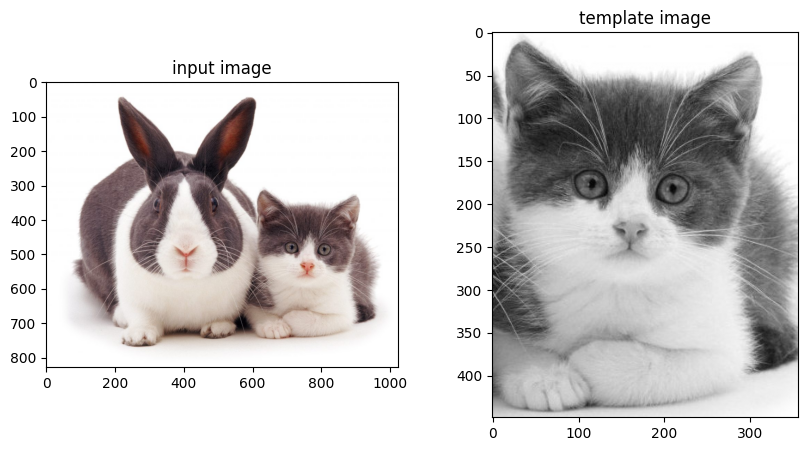

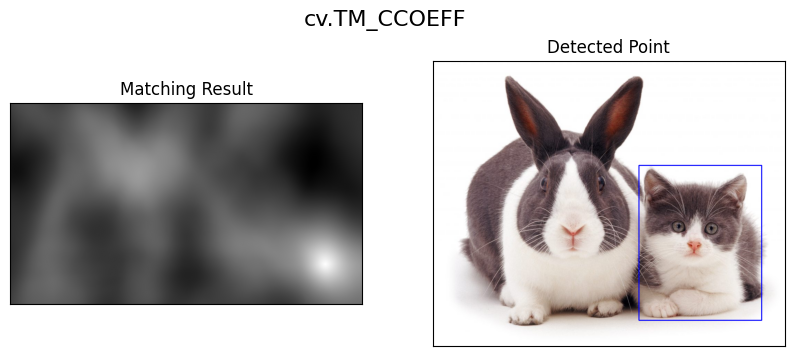

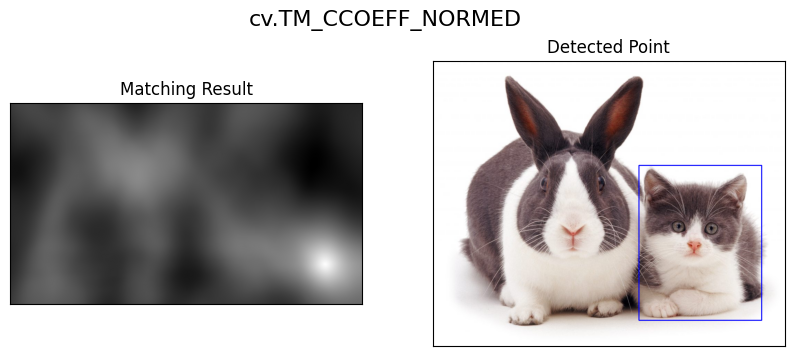

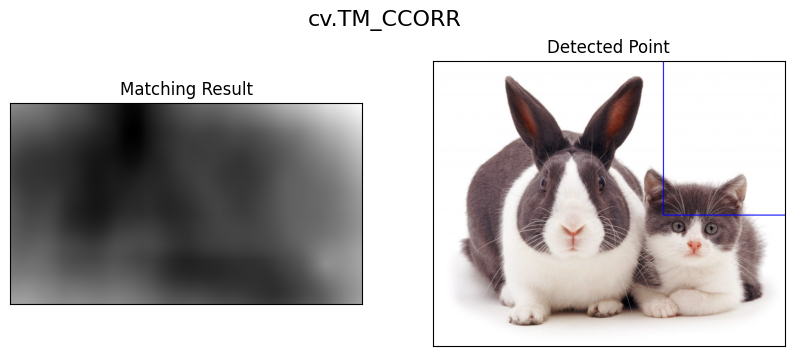

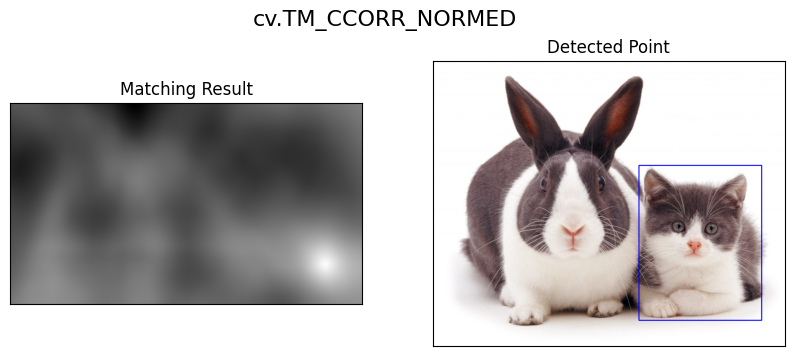

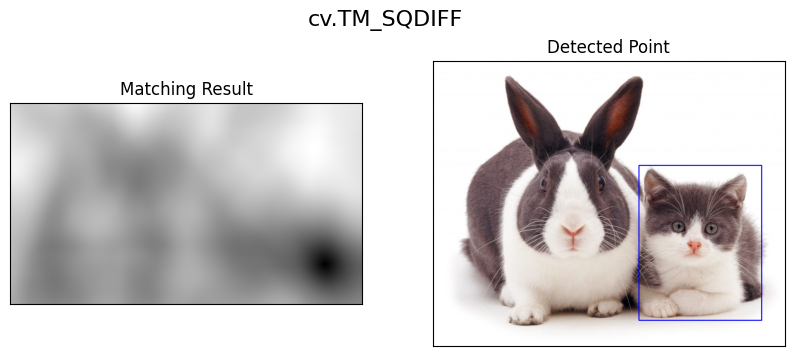

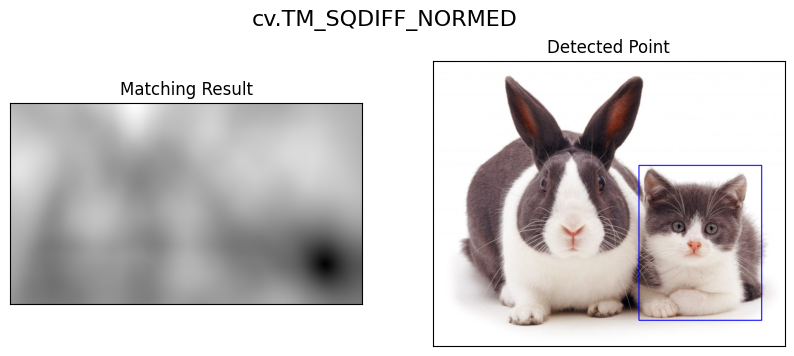

In [3]:
# Path disesuaikan dengan folder di drive
img_rgb = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/cats_and_bunnies.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/cat2_templatejpg.jpg', 0)
w, h = template.shape[::-1]

# Menampilkan gambar awal
plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB)), plt.title('input image')
plt.subplot(122), plt.imshow(template, cmap='gray'), plt.title('template image')
plt.show()

methods = ['cv.TM_CCOEFF', 'cv.TM_CCOEFF_NORMED', 'cv.TM_CCORR',
            'cv.TM_CCORR_NORMED', 'cv.TM_SQDIFF', 'cv.TM_SQDIFF_NORMED']

for meth in methods:
    img = img_rgb.copy()
    method = eval(meth)

    # Apply template Matching
    res = cv.matchTemplate(img_gray, template, method)
    min_val, max_val, min_loc, max_loc = cv.minMaxLoc(res)

    if method in [cv.TM_SQDIFF, cv.TM_SQDIFF_NORMED]:
        top_left = min_loc
    else:
        top_left = max_loc

    bottom_right = (top_left[0] + w, top_left[1] + h)
    cv.rectangle(img, top_left, bottom_right, (255, 0, 0), 2)

    plt.figure(figsize=(10, 4))
    plt.suptitle(meth, fontsize=16)
    plt.subplot(121), plt.imshow(res, cmap='gray'), plt.title('Matching Result'), plt.xticks([]), plt.yticks([])
    plt.subplot(122), plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)), plt.title('Detected Point'), plt.xticks([]), plt.yticks([])
    plt.show()


### 3. Template Matching Tanpa Library (Multiple Object)
Menggunakan `bahrain.jpg` dan `bahrain-template.jpg`.


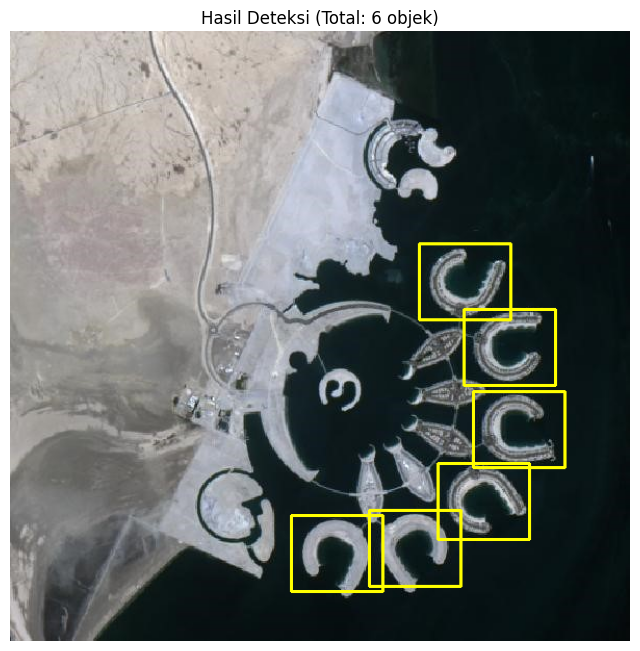

In [4]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca gambar dan template
img_rgb = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/bahrain.jpg')
img_gray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
template = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/bahrain-template.jpg', 0)

w, h = template.shape[::-1]

# 2. Template Matching
res = cv.matchTemplate(img_gray, template, cv.TM_CCOEFF_NORMED)

# 3. TURUNKAN THRESHOLD SECARA DRASTIS
# Jika template Anda sangat spesifik, nilai 0.4 atau 0.45 diperlukan
# untuk menangkap objek yang orientasinya berbeda.
threshold = 0.45
loc = np.where(res >= threshold)

# Kumpulkan semua kotak dan skornya
boxes = []
scores = []
for pt in zip(*loc[::-1]):
    boxes.append([pt[0], pt[1], w, h])
    scores.append(res[pt[1], pt[0]])

# 4. CUSTOM NMS (Lebih andal untuk template matching)
# Kita akan mengambil kotak dengan skor tertinggi, lalu membuang kotak lain yang berdekatan
def custom_nms(boxes, scores, overlap_thresh=0.3):
    if len(boxes) == 0:
        return []

    boxes = np.array(boxes)
    scores = np.array(scores)

    # Ambil indeks berdasarkan skor tertinggi
    indices = np.argsort(scores)[::-1]

    keep = []
    while len(indices) > 0:
        # Ambil kotak dengan skor tertinggi saat ini
        i = indices[0]
        keep.append(i)

        # Hitung area kotak acuan
        x1, y1, w1, h1 = boxes[i]

        # Hitung koordinat untuk kotak pembanding
        xx1 = np.maximum(x1, boxes[indices[1:], 0])
        yy1 = np.maximum(y1, boxes[indices[1:], 1])
        xx2 = np.minimum(x1 + w1, boxes[indices[1:], 0] + boxes[indices[1:], 2])
        yy2 = np.minimum(y1 + h1, boxes[indices[1:], 1] + boxes[indices[1:], 3])

        # Hitung lebar dan tinggi area irisan (intersection)
        w_inter = np.maximum(0, xx2 - xx1 + 1)
        h_inter = np.maximum(0, yy2 - yy1 + 1)

        # Hitung IoU (Intersection over Union)
        intersection = w_inter * h_inter
        union = (w1 * h1) + (boxes[indices[1:], 2] * boxes[indices[1:], 3]) - intersection
        iou = intersection / union

        # Buang kotak yang IoU-nya melebihi overlap_thresh
        # (artinya kotak tersebut menumpuk terlalu banyak dengan kotak acuan)
        inds = np.where(iou <= overlap_thresh)[0]
        indices = indices[inds + 1]

    return keep

# Terapkan Custom NMS
# overlap_thresh=0.2 berarti kotak yang tumpang tindih > 20% akan dibuang
valid_indices = custom_nms(boxes, scores, overlap_thresh=0.2)

# 5. Gambar hasil
if len(valid_indices) > 0:
    for i in valid_indices:
        x, y, box_w, box_h = boxes[i]
        cv.rectangle(img_rgb, (x, y), (x + box_w, y + box_h), (0, 255, 255), 2)

# 6. Tampilkan Hasil
plt.figure(figsize=(8, 8))
plt.imshow(cv.cvtColor(img_rgb, cv.COLOR_BGR2RGB))
plt.title(f'Hasil Deteksi (Total: {len(valid_indices)} objek)')
plt.axis('off')
plt.show()

### 4. Edge Detection (Sobel, Canny, Laplacian)
Menggunakan gambar `car-park.jpg`.


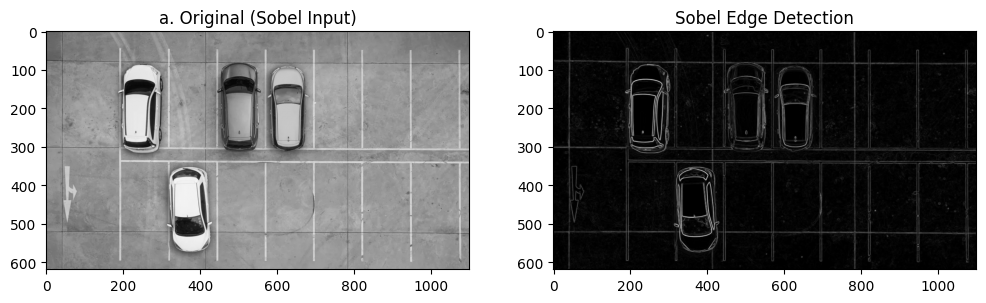

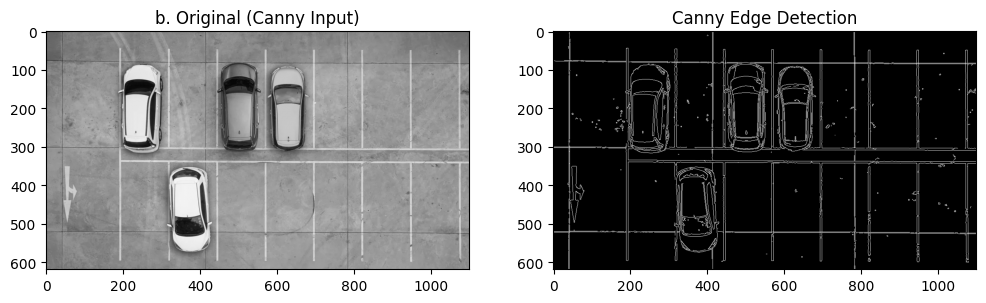

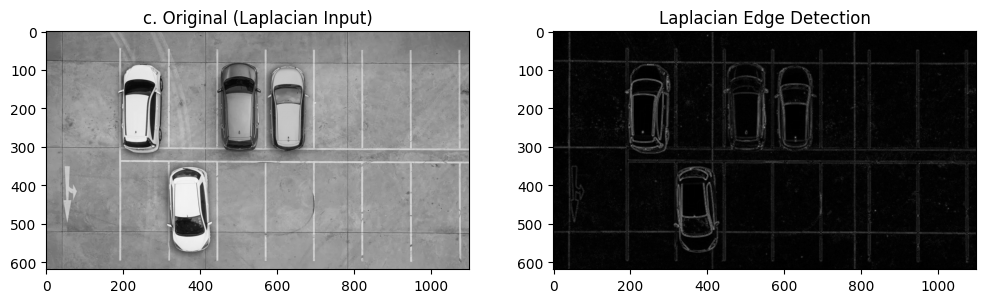

In [5]:
img = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/car-park.jpg', 0)

# Sobel Edge Detection
sobelx = cv.Sobel(img, cv.CV_64F, 1, 0, ksize=3)
sobely = cv.Sobel(img, cv.CV_64F, 0, 1, ksize=3)
sobel_combined = cv.magnitude(sobelx, sobely)

plt.figure(figsize=(12, 4))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('a. Original (Sobel Input)')
plt.subplot(122), plt.imshow(sobel_combined, cmap='gray'), plt.title('Sobel Edge Detection')
plt.show()

# Canny Edge Detection
edges = cv.Canny(img, 100, 200)
plt.figure(figsize=(12, 4))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('b. Original (Canny Input)')
plt.subplot(122), plt.imshow(edges, cmap='gray'), plt.title('Canny Edge Detection')
plt.show()

# Laplacian Edge Detection
# Blur gambar dulu agar lebih baik hasilnya
img_blur = cv.GaussianBlur(img, (3,3), 0)
laplacian = cv.Laplacian(img_blur, cv.CV_64F)
plt.figure(figsize=(12, 4))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('c. Original (Laplacian Input)')
plt.subplot(122), plt.imshow(np.absolute(laplacian), cmap='gray'), plt.title('Laplacian Edge Detection')
plt.show()


### 5. Corner Detection (Harris & Shi-Tomasi)
Menggunakan `chess-board.jpg`.


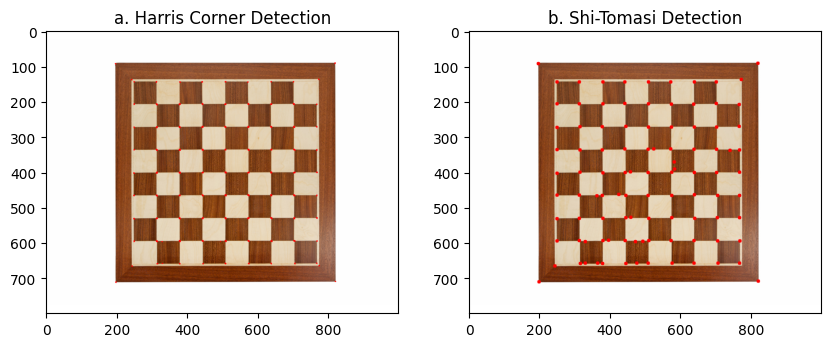

In [6]:
img_harris = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/chess-board.jpg')
gray_harris = cv.cvtColor(img_harris, cv.COLOR_BGR2GRAY)
gray_harris = np.float32(gray_harris)
dst = cv.cornerHarris(gray_harris, 2, 3, 0.04)
dst = cv.dilate(dst, None)
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255]

img_shitomasi = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/chess-board.jpg')
gray_shitomasi = cv.cvtColor(img_shitomasi, cv.COLOR_BGR2GRAY)
corners = cv.goodFeaturesToTrack(gray_shitomasi, 100, 0.01, 10)
corners = np.intp(corners)
for i in corners:
    x, y = i.ravel()
    cv.circle(img_shitomasi, (x, y), 5, (0, 0, 255), -1)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(cv.cvtColor(img_harris, cv.COLOR_BGR2RGB)), plt.title('a. Harris Corner Detection')
plt.subplot(122), plt.imshow(cv.cvtColor(img_shitomasi, cv.COLOR_BGR2RGB)), plt.title('b. Shi-Tomasi Detection')
plt.show()

### 6. Grid Detection (Hough Transform)
Menggunakan `sudoku.jpg`.


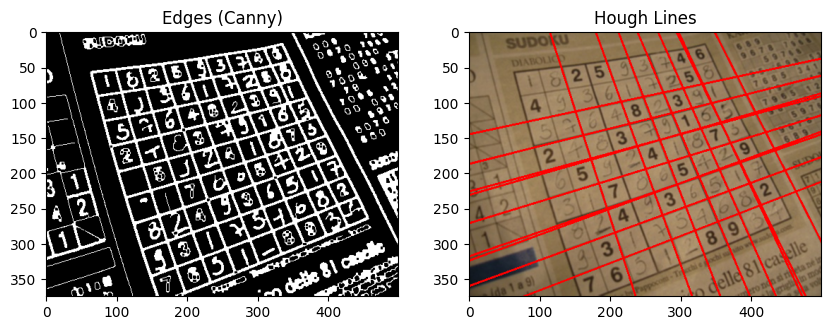

In [7]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/sudoku.jpg')
# Gunakan copy image agar original tidak tertimpa jika sel dijalankan berulang
img_line = img.copy()

gray = cv.cvtColor(img_line, cv.COLOR_BGR2GRAY)
edges = cv.Canny(gray, 50, 150, apertureSize=3)

kernel = np.ones((3,3), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)
edges = cv.erode(edges, kernel, iterations=1)

# UBAH NILAI THRESHOLD DI SINI (Sebelumnya 200, coba naikkan ke 300 atau 350)
lines = cv.HoughLines(edges, 1, np.pi/180, 300)

# Tambahkan pengecekan agar tidak error jika tidak ada garis yang terdeteksi
if lines is not None:
    for line in lines:
        rho, theta = line[0]
        a = np.cos(theta)
        b = np.sin(theta)
        x0 = a * rho
        y0 = b * rho
        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * (a))
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * (a))
        cv.line(img_line, (x1, y1), (x2, y2), (0, 0, 255), 2)

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(edges, cmap='gray'), plt.title('Edges (Canny)')
plt.subplot(122), plt.imshow(cv.cvtColor(img_line, cv.COLOR_BGR2RGB)), plt.title('Hough Lines')
plt.show()

### 7. Contour Detection
Menggunakan `laptop.jpg`.


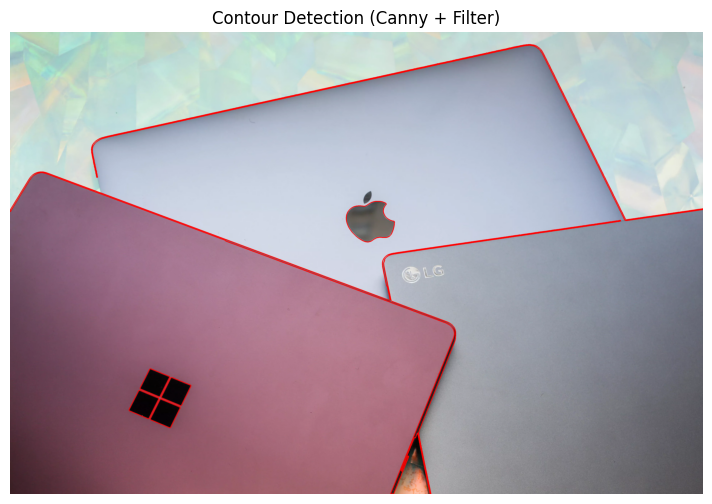

In [8]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca gambar
img = cv.imread('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/laptop.jpg')
img_copy = img.copy() # Simpan salinan asli untuk digambar

# 2. Konversi ke Grayscale dan Blur (untuk mengurangi noise)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
img_blur = cv.GaussianBlur(img_gray, (5, 5), 0)

# 3. Edge Detection menggunakan Canny (bukan threshold biasa)
# Angka 50 dan 150 bisa disesuaikan (semakin kecil semakin sensitif)
edges = cv.Canny(img_blur, 50, 150)

# 4. Morfologi (Dilasi) untuk menyambung garis tepi yang terputus
kernel = np.ones((5,5), np.uint8)
edges = cv.dilate(edges, kernel, iterations=1)

# 5. Cari Kontur
contours, hierarchy = cv.findContours(edges, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

# 6. Filter kontur: Hanya ambil kontur dengan area yang besar (mengabaikan noise kecil)
valid_contours = []
for cnt in contours:
    area = cv.contourArea(cnt)
    if area > 10000: # Sesuaikan angka ini dengan ukuran gambar
        valid_contours.append(cnt)

# 7. Gambar kontur yang sudah difilter (warna merah dalam BGR: (0, 0, 255))
# Karena kita akan menampilkan dengan Matplotlib (RGB), kita gunakan warna Merah di BGR
cv.drawContours(img_copy, valid_contours, -1, (0, 0, 255), 3)

# 8. Tampilkan hasil
plt.figure(figsize=(10, 6))
plt.imshow(cv.cvtColor(img_copy, cv.COLOR_BGR2RGB))
plt.title('Contour Detection (Canny + Filter)')
plt.axis('off') # Opsional: hilangkan sumbu koordinat agar lebih rapi
plt.show()

## D2. Praktikum Feature Matching dan Face Detection
### 8 & 9. Face Detection


In [9]:
# import cv2 as cv
# print(cv.__file__)
# print(getattr(cv, '__version__', 'tidak ada versi'))

In [10]:
# !rm -rf /content/cv2.py /content/cv2

Versi OpenCV: 4.14.0


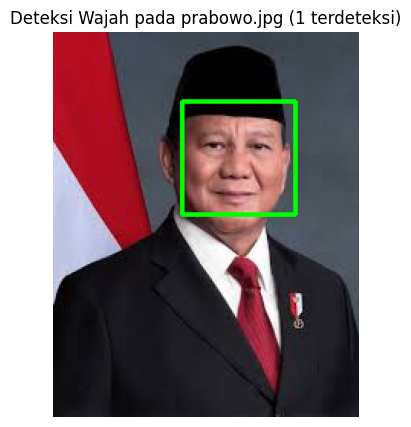

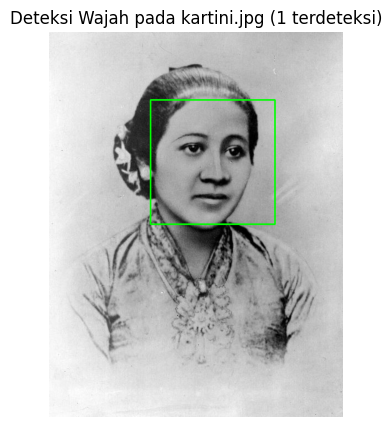

File cat.jpg tidak ditemukan atau gagal dibaca
File mask.jpg tidak ditemukan atau gagal dibaca
File jordan.jpg tidak ditemukan atau gagal dibaca
File solvay.jpg tidak ditemukan atau gagal dibaca


In [11]:
import os
import cv2 as cv
import matplotlib.pyplot as plt

print("Versi OpenCV:", cv.__version__)

def muat_cascade(nama_file):
    """Muat file haarcascade bawaan OpenCV dan pastikan berhasil."""
    clf = cv.CascadeClassifier(os.path.join(cv.data.haarcascades, nama_file))
    if clf.empty():
        raise IOError(f"Gagal memuat {nama_file}")
    return clf

# Folder tempat gambar (dicoba berurutan, dipakai yang pertama ada filenya)
folder_kandidat = [
    '/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/',
    '/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto/Modul 10/',
    '/content/drive/MyDrive/1M30vcqgPBD1PHQpqFUtxWdtiMrwSpijC/',
]
path_folder = next((f for f in folder_kandidat if os.path.isdir(f)), folder_kandidat[0])

def cari_file(nama):
    """Kembalikan path lengkap file jika ditemukan di salah satu folder, else None."""
    for folder in folder_kandidat:
        p = os.path.join(folder, nama)
        if os.path.exists(p):
            return p
    return None

cascade_wajah = muat_cascade('haarcascade_frontalface_default.xml')
cascade_cat   = muat_cascade('haarcascade_frontalcatface.xml')

files = ['prabowo.jpg', 'kartini.jpg', 'cat.jpg', 'mask.jpg', 'jordan.jpg', 'solvay.jpg']

for f in files:
    try:
        p = cari_file(f)
        img = cv.imread(p) if p else None
        if img is None:
            print(f"File {f} tidak ditemukan atau gagal dibaca")
            continue

        gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
        faces = cascade_wajah.detectMultiScale(
            gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30)
        )

        # Untuk kucing, pakai cascade khusus kucing jika wajah manusia tidak terdeteksi
        if f == 'cat.jpg' and len(faces) == 0:
            faces = cascade_cat.detectMultiScale(
                gray, scaleFactor=1.1, minNeighbors=3, minSize=(30, 30)
            )

        for (x, y, w, h) in faces:
            cv.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)

        plt.figure(figsize=(5, 5))
        plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
        plt.title(f'Deteksi Wajah pada {f} ({len(faces)} terdeteksi)')
        plt.axis('off')
        plt.show()

    except Exception as e:
        print(f"Gagal memproses file {f}: {e}")


### 10. Eyes Detection (Prabowo)


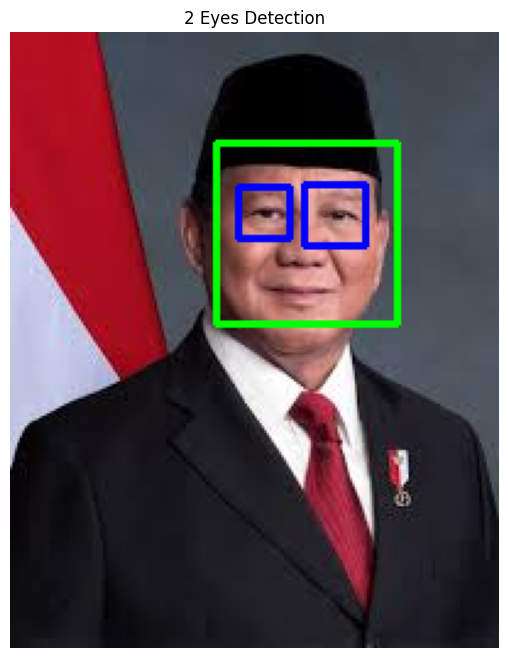

In [25]:
import cv2 as cv
import matplotlib.pyplot as plt

# 1. Inisialisasi Cascade untuk Wajah dan Mata
cascade_wajah = muat_cascade('haarcascade_frontalface_default.xml')
cascade_mata  = muat_cascade('haarcascade_eye.xml')
cascade_mata2 = muat_cascade('haarcascade_eye_tree_eyeglasses.xml')  # cadangan

def cari_dua_mata(roi_gray):
    """Cari tepat 1 mata kiri + 1 mata kanan di dalam ROI wajah (grayscale).
    Return: (daftar kotak mata relatif ROI, True jika ada mata yang diperkirakan)."""
    h, w = roi_gray.shape

    # Mata hanya dicari di bagian atas wajah (membuang hidung/mulut/alis palsu)
    atas, bawah = int(0.10 * h), int(0.62 * h)
    band = cv.equalizeHist(roi_gray[atas:bawah, :])   # memperjelas kontras

    kiri, kanan = None, None
    ideal_y = 0.28 * h - atas                          # perkiraan tinggi mata

    def skor(e, ix):  # makin kecil makin dekat dengan posisi mata yang ideal
        return abs(e[0] + e[2] / 2 - ix * w) / w + abs(e[1] + e[3] / 2 - ideal_y) / h

    for casc in (cascade_mata, cascade_mata2):
        # mulai dari parameter ketat, lalu dilonggarkan sampai kedua mata ketemu
        for mn in (6, 5, 4, 3, 2):
            cand = casc.detectMultiScale(
                band, scaleFactor=1.05, minNeighbors=mn,
                minSize=(max(w // 10, 10),) * 2, maxSize=(w // 2, w // 2)
            )
            L = [e for e in cand if e[0] + e[2] / 2 <  w / 2]   # separuh kiri
            R = [e for e in cand if e[0] + e[2] / 2 >= w / 2]   # separuh kanan
            if kiri  is None and L: kiri  = min(L, key=lambda e: skor(e, 0.30))
            if kanan is None and R: kanan = min(R, key=lambda e: skor(e, 0.70))
            if kiri is not None and kanan is not None:
                break
        if kiri is not None and kanan is not None:
            break

    # Cadangan terakhir: jika hanya 1 mata ketemu, cerminkan ke sisi lain
    diperkirakan = False
    if (kiri is None) != (kanan is None):
        e = kiri if kiri is not None else kanan
        cermin = (int(w - e[0] - e[2]), int(e[1]), int(e[2]), int(e[3]))
        if kiri is None: kiri = cermin
        else:            kanan = cermin
        diperkirakan = True

    hasil = [tuple(int(v) for v in e) for e in (kiri, kanan) if e is not None]
    return [(x, y + atas, ew, eh) for x, y, ew, eh in hasil], diperkirakan

# 2. Membaca gambar
img_path = cari_file('prabowo.jpg')
img = cv.imread(img_path) if img_path else None

if img is None:
    print("Error: Gambar tidak ditemukan. Periksa kembali path file Anda.")
else:
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # 3. Deteksi Wajah (ambil wajah terbesar)
    faces = cascade_wajah.detectMultiScale(gray, 1.1, 5, minSize=(30, 30))

    if len(faces) == 0:
        print("Wajah tidak terdeteksi.")
    else:
        x, y, w, h = max(faces, key=lambda f: f[2] * f[3])
        cv.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)

        # 4. Deteksi 2 mata di dalam ROI wajah
        roi_gray  = gray[y:y+h, x:x+w]
        roi_color = img[y:y+h, x:x+w]
        mata, diperkirakan = cari_dua_mata(roi_gray)

        for (ex, ey, ew, eh) in mata:
            cv.rectangle(roi_color, (ex, ey), (ex + ew, ey + eh), (255, 0, 0), 2)

        # if len(mata) == 2:
        #     cv.putText(img, '2 Eyes Detected', (x, max(y - 10, 20)),
        #                cv.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
        if diperkirakan:
            print("Catatan: satu mata tidak terdeteksi cascade, posisinya diperkirakan dari mata lainnya.")

    # 5. Menampilkan hasil
    plt.figure(figsize=(8, 8))
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('2 Eyes Detection')
    plt.axis('off')
    plt.show()


### 11. Smile Detection (People)


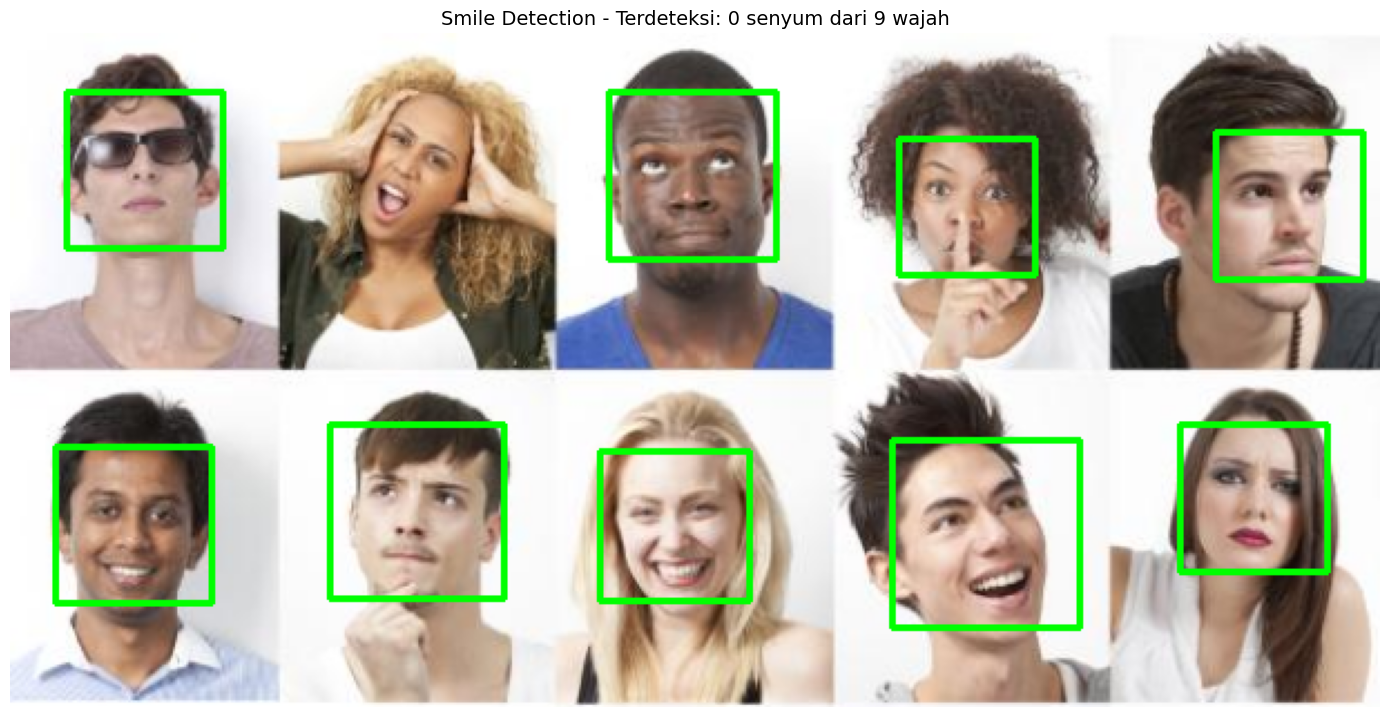

✅ Total wajah terdeteksi: 9
✅ Total senyum terdeteksi: 0


In [40]:
import cv2 as cv
import matplotlib.pyplot as plt
import os

# 1. Inisialisasi cascade (menggantikan fungsi muat_cascade yang tidak terdefinisi)
cascade_wajah = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_frontalface_default.xml')
cascade_smile = cv.CascadeClassifier(cv.data.haarcascades + 'haarcascade_smile.xml')

# 2. Path gambar
path_gambar = '/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/Modul 10- Object Detection Method.jpg'

img = cv.imread(path_gambar)

if img is not None:
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

    # Deteksi wajah dengan parameter yang lebih longgar untuk gambar grid
    faces = cascade_wajah.detectMultiScale(
        gray,
        scaleFactor=1.1,      # Lebih rendah = lebih sensitif
        minNeighbors=5,
        minSize=(50, 50)      # Penting: filter wajah terlalu kecil
    )

    total_smile = 0  # Counter untuk jumlah senyum terdeteksi

    for (x, y, w, h) in faces:
        # Gambar kotak hijau pada wajah
        cv.rectangle(img, (x, y), (x+w, y+h), (0, 255, 0), 2)

        roi_gray = gray[y:y+h, x:x+w]
        roi_color = img[y:y+h, x:x+w]

        # Deteksi senyum dengan parameter yang lebih optimal
        smiles = cascade_smile.detectMultiScale(
            roi_gray,
            scaleFactor=1.5,      # Turunkan dari 1.8 agar lebih sensitif
            minNeighbors=5,      # Turunkan dari 20 (12-15 adalah sweet spot)
            minSize=(20, 20)      # Filter senyum terlalu kecil
        )

        for (sx, sy, sw, sh) in smiles:
            # Gambar kotak merah pada senyum
            cv.rectangle(roi_color, (sx, sy), (sx+sw, sy+sh), (0, 0, 255), 2)
            total_smile += 1

    # Tampilkan hasil dengan ukuran yang lebih besar
    plt.figure(figsize=(14, 8))  # Diperbesar untuk 10 wajah
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title(f'Smile Detection - Terdeteksi: {total_smile} senyum dari {len(faces)} wajah', fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

    print(f"✅ Total wajah terdeteksi: {len(faces)}")
    print(f"✅ Total senyum terdeteksi: {total_smile}")

else:
    print("❌ File gambar tidak ditemukan. Periksa path:")
    print(f"   {path_gambar}")

### 13. Blurring pada wajah (Jordan)


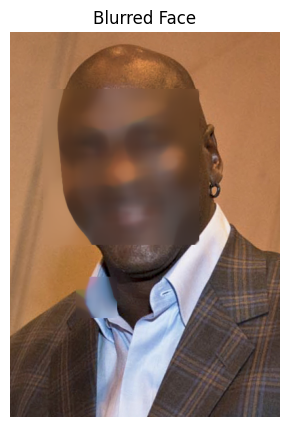

In [45]:
# Cari file menggunakan fungsi pembantu yang sudah didefinisikan sebelumnya
img_path = cari_file('/content/drive/MyDrive/Colab Notebooks/semester 5/PCVk/foto /Modul 10/mjordan.jpg')
img = cv.imread(img_path) if img_path else None

if img is None:
    print("Error: Gambar 'jordan.jpg' tidak ditemukan. Periksa kembali path folder Anda.")
else:
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    faces = cascade_wajah.detectMultiScale(gray, 1.3, 5)

    for (x, y, w, h) in faces:
        # ROI (Region of Interest) dari wajah yang dideteksi
        roi = img[y:y+h, x:x+w]
        # Lakukan blurring pada ROI wajah
        roi = cv.medianBlur(roi, 35)
        # Ganti bagian wajah pada gambar dengan wajah yang sudah diblur
        img[y:y+h, x:x+w] = roi

    plt.figure(figsize=(5, 5))
    plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.title('Blurred Face')
    plt.axis('off')
    plt.show()